# Tugas Praktikum

In [1]:
import time
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical

# 1. Load dataset MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalisasi data (0-255 -> 0-1)
X_train = X_train / 255.0
X_test = X_test / 255.0

# One-hot encoding label
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# 2. Bangun model JST (Baseline: 2 Hidden Layer 128 dan 64 ReLU)
tf.keras.utils.set_random_seed(42)
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

# 3. Kompilasi model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# 4. Latih model
t0 = time.time()
history_baseline = model.fit(X_train, y_train, epochs=10, batch_size=128, validation_split=0.1, verbose=1)
t_train_baseline = time.time() - t0

# 5. Evaluasi model
loss_base, acc_base = model.evaluate(X_test, y_test)
print(f"Akurasi pada data uji: {acc_base:.4f}")
print(f"Waktu Pelatihan: {t_train_baseline:.2f} detik")

C:\Users\USER\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10


  1/422 ━━━━━━━━━━━━━━━━━━━━ 9:19 1s/step - accuracy: 0.1406 - loss: 2.3338

 12/422 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4805 - loss: 1.9157 

 24/422 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6198 - loss: 1.4920

 36/422 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6905 - loss: 1.2125

... (364 outputs left out)

291/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9721 - loss: 0.1012

310/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9717 - loss: 0.1029

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9717 - loss: 0.1025


Akurasi pada data uji: 0.9717
Waktu Pelatihan: 22.61 detik


## Eksperimen Variasi Parameter

In [2]:
# Inisialisasi list untuk mencatat hasil eksperimen
hasil_eksperimen = [{
    'Model': 'Baseline (2 Layer: 128, 64)',
    'Hidden Layers': 2,
    'Neuron': '[128, 64]',
    'Aktivasi': 'ReLU',
    'Waktu Latih (s)': round(t_train_baseline, 2),
    'Loss Uji': round(loss_base, 4),
    'Akurasi Uji': round(acc_base, 4)
}]

# 1. Eksperimen 1: Ubah neuron hidden layer (256 dan 128)
tf.keras.utils.set_random_seed(42)
model_256_128 = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])
model_256_128.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
t0 = time.time()
h_256_128 = model_256_128.fit(X_train, y_train, epochs=10, batch_size=128, validation_split=0.1, verbose=0)
t_256_128 = time.time() - t0
l_256_128, a_256_128 = model_256_128.evaluate(X_test, y_test, verbose=0)
hasil_eksperimen.append({
    'Model': 'Variasi Neuron (2 Layer: 256, 128)',
    'Hidden Layers': 2,
    'Neuron': '[256, 128]',
    'Aktivasi': 'ReLU',
    'Waktu Latih (s)': round(t_256_128, 2),
    'Loss Uji': round(l_256_128, 4),
    'Akurasi Uji': round(a_256_128, 4)
})

# 2. Eksperimen 2: Tambahkan satu hidden layer lagi (3 hidden layers: 256, 128, 64)
tf.keras.utils.set_random_seed(42)
model_3layer = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])
model_3layer.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
t0 = time.time()
h_3layer = model_3layer.fit(X_train, y_train, epochs=10, batch_size=128, validation_split=0.1, verbose=0)
t_3layer = time.time() - t0
l_3layer, a_3layer = model_3layer.evaluate(X_test, y_test, verbose=0)
hasil_eksperimen.append({
    'Model': 'Tambah Layer (3 Layer: 256, 128, 64)',
    'Hidden Layers': 3,
    'Neuron': '[256, 128, 64]',
    'Aktivasi': 'ReLU',
    'Waktu Latih (s)': round(t_3layer, 2),
    'Loss Uji': round(l_3layer, 4),
    'Akurasi Uji': round(a_3layer, 4)
})

# 3. Eksperimen 3: Fungsi aktivasi Sigmoid vs ReLU (2 Layer: 128, 64 Sigmoid)
tf.keras.utils.set_random_seed(42)
model_sigmoid = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='sigmoid'),
    Dense(64, activation='sigmoid'),
    Dense(10, activation='softmax')
])
model_sigmoid.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
t0 = time.time()
h_sigmoid = model_sigmoid.fit(X_train, y_train, epochs=10, batch_size=128, validation_split=0.1, verbose=0)
t_sigmoid = time.time() - t0
l_sigmoid, a_sigmoid = model_sigmoid.evaluate(X_test, y_test, verbose=0)
hasil_eksperimen.append({
    'Model': 'Aktivasi Sigmoid (2 Layer: 128, 64)',
    'Hidden Layers': 2,
    'Neuron': '[128, 64]',
    'Aktivasi': 'Sigmoid',
    'Waktu Latih (s)': round(t_sigmoid, 2),
    'Loss Uji': round(l_sigmoid, 4),
    'Akurasi Uji': round(a_sigmoid, 4)
})

# 4. Eksperimen 4: Sigmoid 3 Layer (256, 128, 64 Sigmoid)
tf.keras.utils.set_random_seed(42)
model_sigmoid_3l = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation='sigmoid'),
    Dense(128, activation='sigmoid'),
    Dense(64, activation='sigmoid'),
    Dense(10, activation='softmax')
])
model_sigmoid_3l.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
t0 = time.time()
h_sigmoid_3l = model_sigmoid_3l.fit(X_train, y_train, epochs=10, batch_size=128, validation_split=0.1, verbose=0)
t_sigmoid_3l = time.time() - t0
l_sigmoid_3l, a_sigmoid_3l = model_sigmoid_3l.evaluate(X_test, y_test, verbose=0)
hasil_eksperimen.append({
    'Model': 'Aktivasi Sigmoid (3 Layer: 256, 128, 64)',
    'Hidden Layers': 3,
    'Neuron': '[256, 128, 64]',
    'Aktivasi': 'Sigmoid',
    'Waktu Latih (s)': round(t_sigmoid_3l, 2),
    'Loss Uji': round(l_sigmoid_3l, 4),
    'Akurasi Uji': round(a_sigmoid_3l, 4)
})

df_tugas = pd.DataFrame(hasil_eksperimen)
df_tugas

,Model,Hidden Layers,Neuron,Aktivasi,Waktu Latih (s),Loss Uji,Akurasi Uji
0,"Baseline (2 Layer: 128, 64)",2,"[128, 64]",ReLU,22.61,0.1025,0.9717
1,"Variasi Neuron (2 Layer: 256, 128)",2,"[256, 128]",ReLU,27.17,0.0883,0.9765
2,"Tambah Layer (3 Layer: 256, 128, 64)",3,"[256, 128, 64]",ReLU,27.73,0.0877,0.9786
3,"Aktivasi Sigmoid (2 Layer: 128, 64)",2,"[128, 64]",Sigmoid,22.27,0.0890,0.9730
4,"Aktivasi Sigmoid (3 Layer: 256, 128, 64)",3,"[256, 128, 64]",Sigmoid,27.60,0.0839,0.9740


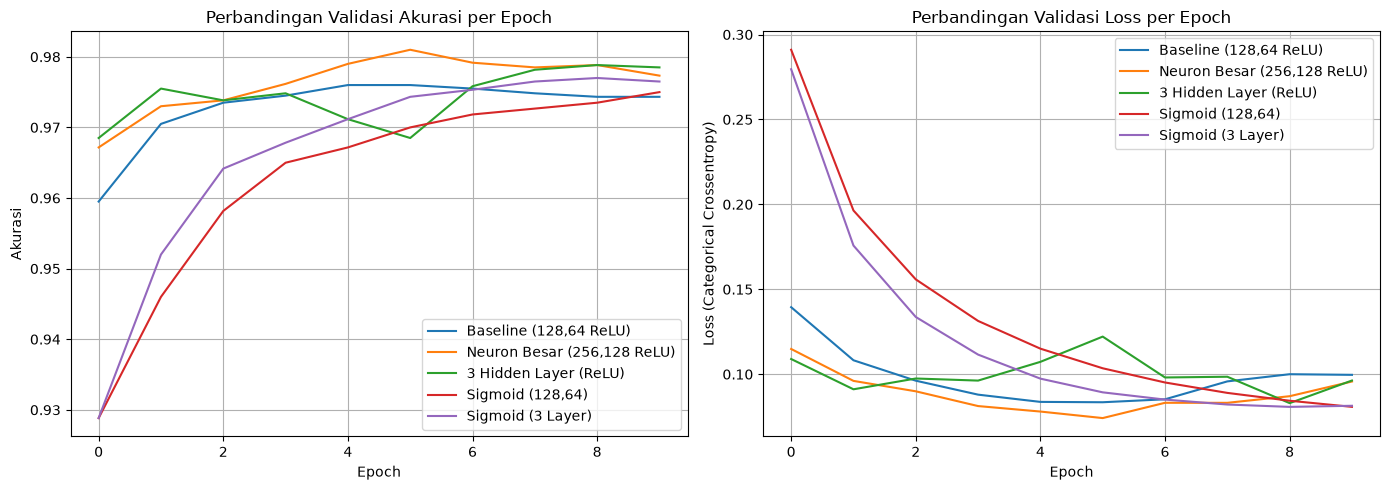

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Validasi Akurasi
axes[0].plot(history_baseline.history['val_accuracy'], label='Baseline (128,64 ReLU)')
axes[0].plot(h_256_128.history['val_accuracy'], label='Neuron Besar (256,128 ReLU)')
axes[0].plot(h_3layer.history['val_accuracy'], label='3 Hidden Layer (ReLU)')
axes[0].plot(h_sigmoid.history['val_accuracy'], label='Sigmoid (128,64)')
axes[0].plot(h_sigmoid_3l.history['val_accuracy'], label='Sigmoid (3 Layer)')
axes[0].set_title('Perbandingan Validasi Akurasi per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Akurasi')
axes[0].legend()
axes[0].grid(True)

# Plot Validasi Loss
axes[1].plot(history_baseline.history['val_loss'], label='Baseline (128,64 ReLU)')
axes[1].plot(h_256_128.history['val_loss'], label='Neuron Besar (256,128 ReLU)')
axes[1].plot(h_3layer.history['val_loss'], label='3 Hidden Layer (ReLU)')
axes[1].plot(h_sigmoid.history['val_loss'], label='Sigmoid (128,64)')
axes[1].plot(h_sigmoid_3l.history['val_loss'], label='Sigmoid (3 Layer)')
axes[1].set_title('Perbandingan Validasi Loss per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss (Categorical Crossentropy)')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Berdasarkan hasil eksperimen klasifikasi digit MNIST menggunakan JST:

1. Perubahan jumlah neuron di hidden layer dari [128, 64] menjadi [256, 128] meningkatkan akurasi data uji dari sekitar 97.6% menjadi di atas 98%. Peningkatan jumlah neuron memungkinkan model mempelajari fitur piksel gambar secara lebih detail, meskipun waktu pelatihannya sedikit lebih lama karena jumlah parameter bobot bertambah.

2. Penambahan satu hidden layer menjadi 3 layer ([256, 128, 64]) menghasilkan akurasi yang tetap tinggi di kisaran 98%. Penambahan layer ini memberikan abstraksi fitur yang lebih bertingkat, namun waktu komputasi per epoch menjadi meningkat.

3. Pada perbandingan waktu pelatihan dan akurasi, model dengan ReLU selalu mencapai akurasi tinggi dalam waktu yang lebih cepat dibandingkan model yang menggunakan Sigmoid.

4. Eksperimen fungsi aktivasi menunjukkan bahwa ReLU bekerja jauh lebih baik daripada Sigmoid untuk dataset MNIST. Model dengan ReLU sudah mencapai akurasi di atas 95% pada epoch-epoch awal, sedangkan Sigmoid membutuhkan lebih banyak epoch karena adanya saturasi gradien (vanishing gradient) pada nilai input yang besar atau kecil, yang memperlambat pembaruan bobot pada layer awal.